# Module 2 POC Training -- FIRE + LongDRScreening + Tianjin

Runs `train_module2_poc.py` against all three Module 2 data sources at once: FIRE and
LongDRScreening (placeholder Stage-2 conditioning unless a Module 1 cache says otherwise,
same as notebook 04) plus Tianjin (real clinical DR grade conditioning, resolved per-eye --
see notebook 05).

The Generator (`DRForestGAN-v2/base_model.py`) uses AdaIN stage conditioning in its
bottleneck, additive to the original channel-concat conditioning. Training pairs can use a
pre-registered, baseline-aligned follow-up image from `module1/train_registration.py` instead
of the raw one, and after training this notebook runs `evaluate_trajectory.py` to report
per-cascade-step FID/PSNR/SSIM against Tianjin's real follow-up images -- not just a
single-step number. A checkpoint from before the AdaIN change will not load into the current
Generator.

**Run this after notebook 04** (FIRE/LongDR Module 1 caches) **and notebook 05** (Tianjin
Module 1 cache + laterality resolution) **have both finished** -- this notebook only reads
their cache outputs from Drive, it doesn't rebuild them.

**EyePACS pretraining:** `USE_NONLONG_PRETRAIN = True` (default, cell before training) fine-tunes
from notebook 09's non-longitudinal pretrained weights (run `models_poc_tianjin_from_nonlong`);
set it False only for the random-init ablation (`models_poc_tianjin`). **`MODULE1_SOURCE`**
(first code cell) must match notebook 04_05's; every run name gets that setting's suffix
(`_drgnet_comb` for the default `'drgnet_combined'`, `_drgnet` for `'drgnet'`). Checkpoints are copied to `Thesis_Datasets/module2_runs/` on Drive for notebook 10.


In [1]:
from google.colab import drive
drive.mount('/content/drive')
# Free Drive space: the training notebooks save checkpoints and caches here (several GB in total).
# Deleted or overwritten files stay in the Drive Trash and still count -- empty it if space is low.
import shutil as _shutil
try:
    _du = _shutil.disk_usage('/content/drive/MyDrive')
    print(f'Google Drive: {_du.free / 1e9:.1f} GB free of {_du.total / 1e9:.1f} GB')
    if _du.free < 10e9:
        print('⚠ Under 10 GB free on Google Drive -- model files may fail to save. Empty the Trash '
              '(drive.google.com/drive/trash) or free space before training.')
except OSError:
    pass

import getpass, os
GITHUB_TOKEN = getpass.getpass('GitHub Personal Access Token (repo scope): ')

REPO_OWNER = 'Mieka068'
REPO_NAME = 'DRProgression'
REPO_BRANCH = 'AllModuleEdits-PreFinals'  # <-- pre-finals fixes (CODE_FIXES_AllModuleEdits-PreFinals.md); 'mod-2-NonLongIntegration' = the earlier runs
REPO_CODE_SUBDIR = 'M2-DRProgression-VerM-module1-fgadr-poc'

DRIVE_DATA_DIR = '/content/drive/MyDrive/Thesis_Datasets'
assert os.path.isdir(DRIVE_DATA_DIR), f"Not found: {DRIVE_DATA_DIR}"

# Which Module 1 models the pipeline uses -- set the SAME value in notebooks 04_05 and 06-10:
#   'drgnet' -- notebook 11's DRG-Net replication checkpoints (module1_runs/drgnet_replication/)
#   'poc'    -- notebooks 02/03's original POC checkpoints (module1_runs/)
# Everything built from Module 1's outputs (Module 1 caches, Module 2 runs, figures) gets a
# '_drgnet' suffix for 'drgnet', so the two pipelines never overwrite each other's results.
MODULE1_SOURCE = 'drgnet_combined'
assert MODULE1_SOURCE in ('drgnet_combined', 'drgnet', 'poc'), MODULE1_SOURCE
# New Drive folders for this branch's runs: every Module 1 cache / Module 2 / Module 3 folder below
# gets RUN_SUFFIX, so the mod-2-NonLongIntegration results stay untouched for before/after
# comparison. '' = read/write the earlier folders again.
RUN_SUFFIX = '_prefinals'
RUN_TAG = {'drgnet_combined': '_drgnet_comb', 'drgnet': '_drgnet', 'poc': ''}[MODULE1_SOURCE] + RUN_SUFFIX
# Module 2 resolution -- the SAME value in notebooks 06, 08, 09 and 10 (item 4.3; the scripts stop
# with an error on a mismatch). Go to 256 only once 128 px training works: both Module 2 stages must
# be retrained (~4x time per epoch) and the registration cache is rebuilt at that size.
MODULE2_IMAGE_SIZE = 128
MODULE1_RUNS = os.path.join(DRIVE_DATA_DIR, 'module1_runs', *(['drgnet_replication'] if MODULE1_SOURCE != 'poc' else []))
# Notebook 11 on this branch writes its models to drgnet_replication<RUN_SUFFIX>/ (tiled evaluation,
# 200 segmentation epochs, optional EyePACS grader); use those once they exist.
if MODULE1_SOURCE != 'poc' and os.path.isdir(os.path.join(MODULE1_RUNS + RUN_SUFFIX, 'segmentation')):
    MODULE1_RUNS += RUN_SUFFIX
elif MODULE1_SOURCE != 'poc' and RUN_SUFFIX:
    print(f'\u26a0 {MODULE1_RUNS + RUN_SUFFIX} not found -- using the earlier Module 1 models in {MODULE1_RUNS}. '
          'Run notebook 11 on this branch first for the re-trained ones.')
# Lesion segmenters: <MODULE1_RUNS>/segmentation/<SEG_MODEL_PREFIX><lesion>/model_2.pth.tar --
# FGADR + DDR combined (notebook 11) or FGADR only. The classifier is FGADR's either way.
SEG_MODEL_PREFIX = 'comb_models_' if MODULE1_SOURCE == 'drgnet_combined' else 'models_FGADR_NO_TATL_'
MODULE1_CACHE_DIR = os.path.join(DRIVE_DATA_DIR, 'module1_cache' + RUN_TAG)
os.makedirs(MODULE1_CACHE_DIR, exist_ok=True)
print('Module 1 source:', MODULE1_SOURCE, '| models:', MODULE1_RUNS, '| caches:', MODULE1_CACHE_DIR)
CACHE_DIR = MODULE1_CACHE_DIR
for _name in ['module1_outputs_fire.pt', 'module1_outputs_longdr.pt', 'module1_outputs_tianjin.pt']:
    _p = os.path.join(CACHE_DIR, _name)
    assert os.path.isfile(_p), (
        f"Not found: {_p} -- run notebook 04_05 first (with the same MODULE1_SOURCE)."
    )
    print('✓', _p)

Mounted at /content/drive
Google Drive: 172.1 GB free of 214.7 GB
GitHub Personal Access Token (repo scope): ··········
Module 1 source: drgnet_combined | models: /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals | caches: /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals
✓ /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals/module1_outputs_fire.pt
✓ /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals/module1_outputs_longdr.pt
✓ /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals/module1_outputs_tianjin.pt


In [2]:
# Unzip the three raw datasets locally (train_module2_poc.py's loaders read images directly
# at training time, not just at cache-build time). Same unzip conventions as notebooks 01/04/05.
import glob, shutil

os.makedirs('/content/data', exist_ok=True)
%cd /content/data
!unzip -q -n "$DRIVE_DATA_DIR/FIRE_dataset.zip"
!unzip -q -n "$DRIVE_DATA_DIR/LongDRScreening_20150209.zip" -d LongDRScreening_20150209
!unzip -q -n "$DRIVE_DATA_DIR/retinal-dr-longitudinal.zip" -d _tianjin_extract_raw

_manifest_candidates = glob.glob('/content/data/_tianjin_extract_raw/**/corrected_manifest.csv', recursive=True)
assert _manifest_candidates, 'No corrected_manifest.csv found -- see notebook 05 for troubleshooting.'
_tianjin_root = os.path.dirname(_manifest_candidates[0])
TIANJIN_DIR = '/content/data/retinal-dr-longitudinal'
if _tianjin_root != TIANJIN_DIR and not os.path.exists(TIANJIN_DIR):
    os.symlink(_tianjin_root, TIANJIN_DIR)

print('FIRE Images present   :', os.path.isdir('/content/data/FIRE_dataset/FIRE/Images'))
print('LongDR norm present   :', os.path.isdir('/content/data/LongDRScreening_20150209/FundusImagesNormalized'))
print('Tianjin manifest found:', os.path.isfile(os.path.join(TIANJIN_DIR, 'corrected_manifest.csv')))

/content/data
FIRE Images present   : True
LongDR norm present   : True
Tianjin manifest found: True


In [3]:
# Clone this repo. Skips cleanly if already cloned in this runtime.
%cd /content
if not os.path.isdir(f'/content/{REPO_NAME}'):
    !git clone --branch {REPO_BRANCH} https://{GITHUB_TOKEN}@github.com/{REPO_OWNER}/{REPO_NAME}.git {REPO_NAME}

REPO_CODE_DIR = f'/content/{REPO_NAME}/{REPO_CODE_SUBDIR}'
assert os.path.isdir(REPO_CODE_DIR), f"Not found: {REPO_CODE_DIR} -- check REPO_BRANCH/REPO_CODE_SUBDIR above"

%cd {REPO_CODE_DIR}
!pip install -q pandas openpyxl segmentation-models-pytorch torchmetrics torch-fidelity opencv-python-headless

/content
Cloning into 'DRProgression'...
remote: Enumerating objects: 945, done.
remote: Counting objects: 100% (111/111), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 945 (delta 103), reused 98 (delta 98), pack-reused 834 (from 1)
Receiving objects: 100% (945/945), 24.89 MiB | 20.84 MiB/s, done.
Resolving deltas: 100% (588/588), done.
/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc


In [4]:
# Laterality resolution: Organized_Data of Patients.xlsx grades DR per eye (OS/OD), not per
# patient, and corrected_manifest.csv doesn't say which eye a row is -- tianjin_dataset.py /
# module3/dataset.py both require laterality_resolved.csv to exist in TIANJIN_DIR before they
# can run. Reuse a Drive-persisted copy if one already exists (resolving ~1,100 images takes a
# few minutes); otherwise compute it fresh here and persist it to Drive for next time.
# This branch re-tuned module1/resolve_eye_laterality.py (item 7.1), so it gets its own copy
# (module1_cache<RUN_SUFFIX>/); the settings come from notebook 11's EyePACS validation when it exists.
# _v2: the first file on this branch used the EyePACS validation's convention at only ~61 % accuracy
# (EyePACS mixes mirrored and non-mirrored images) -> 20.6 % of patients had both eyes labelled alike.
LATERALITY_DRIVE_PATH = os.path.join(DRIVE_DATA_DIR, 'module1_cache' + RUN_SUFFIX, 'laterality_resolved_v2.csv')
LATERALITY_VALIDATION = os.path.join(DRIVE_DATA_DIR, 'module1_cache' + RUN_SUFFIX, 'laterality_eyepacs_validation.json')
LATERALITY_LOCAL_PATH = os.path.join(TIANJIN_DIR, 'laterality_resolved.csv')

if os.path.isfile(LATERALITY_DRIVE_PATH):
    import shutil
    shutil.copy(LATERALITY_DRIVE_PATH, LATERALITY_LOCAL_PATH)
    print(f'✓ Reused laterality_resolved.csv from Drive: {LATERALITY_DRIVE_PATH}')
else:
    %cd {REPO_CODE_DIR}
    # LATERALITY_DISC_LEFT_IS: which eye a left-of-centre optic disc means in Tianjin's images. None =
    # the script's default ('OD', what every earlier run used), unless notebook 11's EyePACS validation
    # is clearly reliable (>= 80 % accuracy). Check a few Tianjin images of known right eyes by eye and
    # set 'OD' or 'OS' here -- that is the real answer (after changing it, delete laterality_resolved_v2.csv
    # on Drive so it is recomputed).
    LATERALITY_DISC_LEFT_IS = None
    _lat_args = ''
    _b = None
    if os.path.isfile(LATERALITY_VALIDATION):
        import json as _json
        _b = _json.load(open(LATERALITY_VALIDATION))['best']
    if LATERALITY_DISC_LEFT_IS:
        _lat_args = f' --disc-left-is {LATERALITY_DISC_LEFT_IS}'
        print(f'Laterality: --disc-left-is {LATERALITY_DISC_LEFT_IS} (set by hand)')
    elif _b and _b['accuracy_on_decided'] >= 0.8:
        _lat_args = (f" --disc-left-is {_b['disc_left_is']} --margin {_b['margin']}"
                     + (' --legacy-estimator' if _b['estimator'] == 'legacy' else ''))
        print(f"Laterality settings from the EyePACS validation: {_lat_args} "
              f"(accuracy {_b['accuracy_on_decided']:.1%}, {_b['uncertain_rate']:.1%} uncertain)")
    else:
        print('\u26a0 Laterality: script defaults (--disc-left-is OD --margin 0.1) -- '
              + (f"the EyePACS validation is too weak to use ({_b['accuracy_on_decided']:.1%} accuracy). "
                 if _b else 'no EyePACS validation. ')
              + 'Set LATERALITY_DISC_LEFT_IS after checking a few Tianjin images by eye.')
    !python module1/resolve_eye_laterality.py --dataset-dir "{TIANJIN_DIR}"{_lat_args}
    # Read the printed same-eye disagreement rate above before trusting this for training --
    # see resolve_eye_laterality.py's module docstring (>5% disagreement means the heuristic
    # needs tuning).
    os.makedirs(os.path.dirname(LATERALITY_DRIVE_PATH), exist_ok=True)
    import shutil
    shutil.copy(LATERALITY_LOCAL_PATH, LATERALITY_DRIVE_PATH)
    print(f'✓ Computed and persisted laterality_resolved.csv to Drive: {LATERALITY_DRIVE_PATH}')

✓ Reused laterality_resolved.csv from Drive: /content/drive/MyDrive/Thesis_Datasets/module1_cache_prefinals/laterality_resolved_v2.csv


In [5]:
# Trains the training-only affine registration network and pre-warps every baseline<->follow-up
# pair (all 3 sources) so train_module2_poc.py can condition on baseline-aligned follow-up images.
# Saved to Drive and REUSED on later sessions: registration training is random, so regenerating it
# would hand a resumed Module 2 run different aligned images than it started with. Delete the
# folder below to rebuild it (e.g. after the datasets change). Independent of MODULE1_SOURCE.
# On this branch (items 5.1/5.2): Tianjin pairs whose recovered pairing quality is below
# TIANJIN_MIN_PAIR_QUALITY are dropped (registration AND training); every run first validates the
# warps against FIRE's ground-truth control points (identity vs. network vs. SIFT + RANSAC, printed
# and saved as fire_registration_validation.json). REGISTRATION_METHOD = 'sift' builds the cache with
# the classical registration instead -- use it if the network barely beats identity. Each setting
# gets its own folder (RUN_SUFFIX, method, size), so the earlier registration/ cache is kept.
TIANJIN_MIN_PAIR_QUALITY = 0.5   # None = keep every pair (earlier behaviour)
REGISTRATION_METHOD = 'net'      # 'net' (self-supervised affine network) or 'sift'
REG_DIR = os.path.join(DRIVE_DATA_DIR, 'module2_runs', 'registration' + RUN_SUFFIX
                       + ('' if REGISTRATION_METHOD == 'net' else f'_{REGISTRATION_METHOD}')
                       + ('' if MODULE2_IMAGE_SIZE == 128 else f'_{MODULE2_IMAGE_SIZE}'))
QUALITY_ARGS = f' --tianjin-min-pair-quality {TIANJIN_MIN_PAIR_QUALITY}' if TIANJIN_MIN_PAIR_QUALITY is not None else ''
REGISTRATION_CACHE = os.path.join(REG_DIR, 'registered_followups.pt')
if os.path.isfile(REGISTRATION_CACHE):
    print('✓ Reusing registration cache from Drive:', REGISTRATION_CACHE)
else:
    os.makedirs(REG_DIR, exist_ok=True)
    %cd {REPO_CODE_DIR}/module1
    !python train_registration.py --image-size {MODULE2_IMAGE_SIZE} \
        --fire-dir /content/data/FIRE_dataset \
        --longdr-dir /content/data/LongDRScreening_20150209 \
        --tianjin-dir "{TIANJIN_DIR}"{QUALITY_ARGS} \
        --num-epochs 10 --method {REGISTRATION_METHOD} \
        --checkpoint-out "{REG_DIR}/registration_net.ckpt" \
        --validation-out "{REG_DIR}/fire_registration_validation.json" \
        --cache-out "{REGISTRATION_CACHE}"


/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc/module1
Training-only affine registration network
Device: cuda

[1/3] Loading FIRE + LongDRScreening + Tianjin pairs...
  Searching: /content/data/FIRE_dataset/FIRE/Images
✓ Found 14 pairs in FIRE Category A
✓ Found 559 pairs in LongDRScreening (FundusImagesNormalized)
  Quality filter (>= 0.5): 1115 -> 346 pairs
  Reading grades from sheet 'Baseline': patient_id <- 'ID', OS <- 'OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', OD <- 'OD Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', worse-eye <- 'At-risk Eye Grade（Worse eye）'
  Reading grades f

In [6]:
# Locate the same Module 1 checkpoints notebooks 04/05 already found on Drive -- the cascade
# re-segments/re-grades each synthesized step with Module 1 itself (not just the GAN), so
# evaluate_trajectory.py needs these too, not just the module1_cache .pt files. Before training on
# this branch: the grader also scores every epoch's val outputs for best-epoch selection (item 5.3).
import glob

SEG_DIR   = os.path.join(MODULE1_RUNS, 'segmentation')
# Module 1 grader: 'eyepacs' (default) = DRG-Net's classifier trained on EyePACS (notebook 11, training
# capped at 3000 images/grade); 'fgadr' = the FGADR grader. Notebook 04_05's grader-comparison cell scores
# both on Tianjin's clinical grades -- set the one it recommends in notebooks 04_05, 06, 08, 09 and 10.
# With 'eyepacs' and no EyePACS grader on Drive, the FGADR one is used.
CLASSIFIER_RUN = 'eyepacs'
if not glob.glob(os.path.join(MODULE1_RUNS, 'classification', CLASSIFIER_RUN, 'saves', '*.pt')):
    print(f'\u26a0 No {CLASSIFIER_RUN} grader in {MODULE1_RUNS} yet -- using the FGADR one')
    CLASSIFIER_RUN = 'fgadr'
CLS_SAVES = os.path.join(MODULE1_RUNS, 'classification', CLASSIFIER_RUN, 'saves')
# Classifier input normalisation must match its training config (eyepacs_poc.yaml differs).
CLS_NORM_ARGS = ' --classifier-norm eyepacs' if CLASSIFIER_RUN == 'eyepacs' else ''

# EyePACS: best_validation_weights.pt (picked on the Kaggle public test, kept apart from its test set);
# FGADR: final_weights.pt (its "validation" set IS its test set, so the best-validation pick is optimistic).
_pref  = (['best_validation_weights.pt', 'final_weights.pt'] if CLASSIFIER_RUN == 'eyepacs'
          else ['final_weights.pt', 'best_validation_weights.pt'])
_cands = [os.path.join(CLS_SAVES, n) for n in _pref] + sorted(
    glob.glob(os.path.join(CLS_SAVES, '*.pt')), key=os.path.getmtime, reverse=True)
CLS_CKPT = next((p for p in _cands if os.path.isfile(p)), None)
assert CLS_CKPT, f"No classifier .pt in {CLS_SAVES} -- run notebook 02/03 (MODULE1_SOURCE='poc') or 11 ('drgnet' / 'drgnet_combined') first"

EX_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'ex', 'model_2.pth.tar')
MA_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'ma', 'model_2.pth.tar')
for _p in (CLS_CKPT, EX_CKPT, MA_CKPT):
    assert os.path.isfile(_p), f"missing checkpoint: {_p} -- run notebook 02/03 (MODULE1_SOURCE='poc') or 11 ('drgnet' / 'drgnet_combined') first"
print('classifier :', CLS_CKPT)
print('EX seg     :', EX_CKPT)
print('MA seg     :', MA_CKPT)
# HE/SE checkpoints -- included automatically once they exist on Drive, omitted otherwise
# (apply_to_progression_data.py/evaluate_trajectory.py both leave a lesion channel out rather
# than fail if no checkpoint is passed for it).
HE_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'he', 'model_2.pth.tar')
SE_CKPT = os.path.join(SEG_DIR, SEG_MODEL_PREFIX + 'se', 'model_2.pth.tar')
print('HE seg     :', HE_CKPT if os.path.isfile(HE_CKPT) else 'not trained yet')
print('SE seg     :', SE_CKPT if os.path.isfile(SE_CKPT) else 'not trained yet')

classifier : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/classification/eyepacs/saves/best_validation_weights.pt
EX seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_models_ex/model_2.pth.tar
MA seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_models_ma/model_2.pth.tar
HE seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_models_he/model_2.pth.tar
SE seg     : /content/drive/MyDrive/Thesis_Datasets/module1_runs/drgnet_replication_prefinals/segmentation/comb_models_se/model_2.pth.tar


In [7]:
# Start Module 2 from notebook 09's EyePACS (non-longitudinal) pretraining -- the method.
# Pretraining ablation (item 5.7): after the main run, set this False and run the notebook again
# (Runtime -> Run all). That run (random init, models_poc_tianjin{RUN_TAG}) has its own Drive folder,
# samples and figures, so the two runs' trajectory_eval_results.json compare directly.
USE_NONLONG_PRETRAIN = True

NONLONG_DIR = os.path.join(DRIVE_DATA_DIR, 'module2_runs', 'nonlong_pretrain' + RUN_TAG)
if USE_NONLONG_PRETRAIN:
    for _f in ('final-G.ckpt', 'final-D.ckpt'):
        assert os.path.isfile(os.path.join(NONLONG_DIR, _f)), (
            f"{NONLONG_DIR}/{_f} missing -- run notebook 09 first (same MODULE1_SOURCE), "
            "or set USE_NONLONG_PRETRAIN = False")
    INIT_ARGS = (f' --init-generator "{NONLONG_DIR}/final-G.ckpt"'
                 f' --init-discriminator "{NONLONG_DIR}/final-D.ckpt"')
    MODULE2_RUN_NAME = 'models_poc_tianjin_from_nonlong' + RUN_TAG
else:
    INIT_ARGS = ''
    MODULE2_RUN_NAME = 'models_poc_tianjin' + RUN_TAG
print('Module 2 run:', MODULE2_RUN_NAME, '| init:', INIT_ARGS or 'random')


Module 2 run: models_poc_tianjin_from_nonlong_drgnet_comb_prefinals | init:  --init-generator "/content/drive/MyDrive/Thesis_Datasets/module2_runs/nonlong_pretrain_drgnet_comb_prefinals/final-G.ckpt" --init-discriminator "/content/drive/MyDrive/Thesis_Datasets/module2_runs/nonlong_pretrain_drgnet_comb_prefinals/final-D.ckpt"


In [8]:
# --fire-dir / --longdr-dir / --tianjin-dir MUST be passed explicitly: train_module2_poc.py's
# own argparse defaults resolve relative to the cloned repo's working directory, not where the
# data actually lives on the Colab VM (see combined_dataset.py / train_module2_poc.py docstrings).
# --eval-batches raised from the script's own unexamined default of 5 to 15 (with the
# default batch-size=4, that's ~60 samples, above min-n-for-fid=50) so FID/KID actually
# compute rather than reporting None -- see IMPLEMENTATION_PLAN_3.md Task L and
# image_quality_metrics.py. Raise further if the combined dataset has more to spare.
#
# MODULE2_EPOCHS: 100 (was 50). With n_critic = 5 (train_module2_poc.py's default on this branch) the
# Generator is updated once per 5 batches, so it needs more epochs for the same number of G steps
# (printed as 'G steps'); go to 200 only once the val curve shows training still helping. Training state is saved every epoch on the runtime's disk and copied to
# Drive (resume_state.pt in this run's Drive folder) every 10 epochs and after the last one --
# rewriting it on Drive every epoch would fill the Drive with old copies. If Colab disconnects,
# re-run this notebook: training continues from the last Drive copy (at most 9 epochs redone).
# Raising MODULE2_EPOCHS later and re-running also continues the same run up to the new total.
# To start over, delete that resume_state.pt and restart the runtime.
#
# Best-epoch saving: 10% of the eyes/patients (--val-fraction 0.1) are held out of training;
# after every epoch the Generator is scored on them (L1 between its synthesized follow-up and
# the real one) and the best epoch is saved as best-G.ckpt -- that is the model every later
# step uses (evaluation below, notebooks 08 and 10). final-G.ckpt is the last epoch. The
# printed "val L1 ... new best" lines show which epoch won.
MODULE2_EPOCHS = 100
# Best epoch (item 5.3) = lowest val L1 - SELECTION_ALPHA x Module 1 agreement with the target stage on
# the val pairs' synthesized follow-ups (CLS_CKPT above; SELECTION_ALPHA = 0 -> val L1 only, the earlier
# rule). EARLY_STOP_PATIENCE: stop after that many epochs without a better score (0 = run all epochs).
# Stage 0 baselines (item 7.2): 0 keeps every baseline grade (the default -- more data, documented as
# in scope); 1 keeps only eyes that start at >= mild NPDR (the manuscript's scope). Use the same value
# in notebooks 06 and 07.
MIN_BASELINE_GRADE = 0
SELECTION_ALPHA = 0.1
EARLY_STOP_PATIENCE = 25
MODULE2_RESUME_STATE = os.path.join(DRIVE_DATA_DIR, 'module2_runs', MODULE2_RUN_NAME, 'resume_state.pt')
%cd {REPO_CODE_DIR}
!python train_module2_poc.py --image-size {MODULE2_IMAGE_SIZE} \
    --fire-dir /content/data/FIRE_dataset \
    --longdr-dir /content/data/LongDRScreening_20150209 \
    --tianjin-dir "{TIANJIN_DIR}" \
    --fire-module1-cache "{MODULE1_CACHE_DIR}/module1_outputs_fire.pt" \
    --longdr-module1-cache "{MODULE1_CACHE_DIR}/module1_outputs_longdr.pt" \
    --tianjin-module1-cache "{MODULE1_CACHE_DIR}/module1_outputs_tianjin.pt" \
    --registration-cache "{REGISTRATION_CACHE}"{QUALITY_ARGS} \
    --num-epochs {MODULE2_EPOCHS} \
    --resume-state "{MODULE2_RESUME_STATE}" \
    --save-dir ./DRForestGAN-v2/stargan/{MODULE2_RUN_NAME}/{INIT_ARGS} \
    --sample-dir ./training_samples_poc/{MODULE2_RUN_NAME}/ \
    --selection-classifier-checkpoint "{CLS_CKPT}"{CLS_NORM_ARGS} --selection-alpha {SELECTION_ALPHA} \
    --early-stop-patience {EARLY_STOP_PATIENCE} --tianjin-min-baseline-grade {MIN_BASELINE_GRADE} \
    --num-workers 2 \
    --val-fraction 0.1 \
    --eval-batches 15 \
    --fid-n-bootstrap 10

/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
Classifier normalisation: eyepacs mean=[0.425753653049469, 0.29737451672554016, 0.21293757855892181] std=[0.27670302987098694, 0.20240527391433716, 0.1686241775751114]
Module 2 POC training (real Module 1 conditioning)
Device: cuda
fire_module1_cache_path: /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals/module1_outputs_fire.pt
longdr_module1_cache_path: /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals/module1_outputs_longdr.pt
tianjin_dir: /content/data/retinal-dr-longitudinal
tianjin_module1_cache_path: /content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals/module1_outputs_tianjin.pt
condition_on: followup grade

[1/4] Loading combined dataset (with real Module 1 conditioning where cached)...
✓ Loaded Module 1 cache: 268 images (/content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals/module1_outputs_fire.pt)
✓ Loaded registration ca

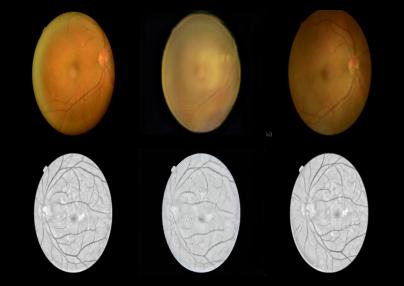

{
  "num_epochs": 100,
  "image_size": 128,
  "num_pairs": 917,
  "effective_samples": 3296,
  "g_lr": 0.0001,
  "d_lr": 0.0001,
  "beta1": 0.0,
  "beta2": 0.9,
  "n_critic": 5,
  "model_arch": "prefinals",
  "batch_size": 8,
  "lambda_cls": 1.0,
  "fire_module1_cache_path": "/content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals/module1_outputs_fire.pt",
  "longdr_module1_cache_path": "/content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals/module1_outputs_longdr.pt",
  "tianjin_dir": "/content/data/retinal-dr-longitudinal",
  "tianjin_module1_cache_path": "/content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals/module1_outputs_tianjin.pt",
  "registration_cache_path": "/content/drive/MyDrive/Thesis_Datasets/module2_runs/registration_prefinals/registered_followups.pt",
  "init_generator_path": "/content/drive/MyDrive/Thesis_Datasets/module2_runs/nonlong_pretrain_drgnet_comb_prefinals/final-G.ckpt",
  "init_discriminator_path": 

In [9]:
from IPython.display import Image as IPImage, display
import glob, json, os

# Sorted by epoch number (plain sorted() puts epoch_9.jpg after epoch_10.jpg ... and shows it as the last).
samples = sorted(glob.glob(f'{REPO_CODE_DIR}/training_samples_poc/{MODULE2_RUN_NAME}/epoch_*.jpg'),
                 key=lambda p: int(os.path.basename(p)[len('epoch_'):-len('.jpg')]))
if samples:
    display(IPImage(samples[-1]))
else:
    print(f'No training_samples_poc/{MODULE2_RUN_NAME}/epoch_*.jpg found -- the training cell above did not finish. Read its output.')

rp = f'{REPO_CODE_DIR}/DRForestGAN-v2/stargan/{MODULE2_RUN_NAME}/poc_results.json'
print(json.dumps(json.load(open(rp)), indent=2) if os.path.isfile(rp) else f'{rp} not found')

In [10]:
# Persist this run's checkpoints + poc_results.json to Drive (the runtime disk is wiped when the
# session ends) -- notebook 10 loads the Generator from here.
import shutil
_src = f'{REPO_CODE_DIR}/DRForestGAN-v2/stargan/{MODULE2_RUN_NAME}'
_dst = os.path.join(DRIVE_DATA_DIR, 'module2_runs', MODULE2_RUN_NAME)
# Per-epoch {epoch}-G.ckpt snapshots stay on the runtime (~33 MB each, not used downstream):
# Drive gets best-G.ckpt, final-G.ckpt, resume state and results only.
shutil.copytree(_src, _dst, dirs_exist_ok=True, ignore=shutil.ignore_patterns('[0-9]*-G.ckpt'))
print('✓ Copied', _src, '->', _dst)
for _f in ('best-G.ckpt', 'final-G.ckpt'):
    _a, _b = os.path.join(_src, _f), os.path.join(_dst, _f)
    if os.path.isfile(_a):
        assert os.path.isfile(_b) and os.path.getsize(_b) == os.path.getsize(_a), (
            f'{_f} not fully saved to Drive ({_dst}) -- is your Google Drive full? Check drive.google.com/settings/storage and empty the Trash, then re-run this cell.')

✓ Copied /content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc/DRForestGAN-v2/stargan/models_poc_tianjin_from_nonlong_drgnet_comb_prefinals -> /content/drive/MyDrive/Thesis_Datasets/module2_runs/models_poc_tianjin_from_nonlong_drgnet_comb_prefinals


In [11]:
# Per-cascade-step FID/PSNR/SSIM against Tianjin's real follow-up images (the only source with
# a real grade on both baseline and follow-up -- FIRE/LongDR can't participate, see
# evaluate_trajectory.py's module docstring), plus Module 1's own re-grading consistency at
# every cascade step (generate, re-segment, re-grade, feed forward). The single-step metrics
# from the training cell above don't report this.
%cd {REPO_CODE_DIR}
_extra_seg_args = ''
if os.path.isfile(HE_CKPT):
    _extra_seg_args += f' --seg-checkpoint HE={HE_CKPT}'
if os.path.isfile(SE_CKPT):
    _extra_seg_args += f' --seg-checkpoint SE={SE_CKPT}'

# Evaluates the best-epoch Generator (best-G.ckpt, picked on held-out pairs). Falls back to
# final-G.ckpt (last epoch; also the only one with --val-fraction 0), then -- if the training
# cell got cut short before writing either -- to the latest numbered {epoch}-G.ckpt, and says so.
GEN_SAVE_DIR = f'{REPO_CODE_DIR}/DRForestGAN-v2/stargan/{MODULE2_RUN_NAME}'
_best = os.path.join(GEN_SAVE_DIR, 'best-G.ckpt')
_final = os.path.join(GEN_SAVE_DIR, 'final-G.ckpt')
if os.path.isfile(_final) and os.path.isfile(_best):
    GENERATOR_CKPT = _best
elif os.path.isfile(_final):
    GENERATOR_CKPT = _final
else:
    _epoch_ckpts = glob.glob(os.path.join(GEN_SAVE_DIR, '*-G.ckpt'))
    assert _epoch_ckpts, f"No checkpoint at all in {GEN_SAVE_DIR} -- the training cell above did not finish a single epoch."
    GENERATOR_CKPT = max(_epoch_ckpts, key=lambda p: int(os.path.basename(p).split('-')[0]))
    print(f"⚠ final-G.ckpt not found -- training was likely interrupted. Using {GENERATOR_CKPT} instead "
          "(an earlier epoch, not the full run).")

# Saved on Drive next to the run (the runtime disk is wiped when the session ends).
TRAJ_EVAL_JSON = os.path.join(DRIVE_DATA_DIR, 'module2_runs', MODULE2_RUN_NAME, 'trajectory_eval_results.json')
!python evaluate_trajectory.py --image-size {MODULE2_IMAGE_SIZE} \
    --tianjin-dir "{TIANJIN_DIR}" \
    --tianjin-module1-cache "{MODULE1_CACHE_DIR}/module1_outputs_tianjin.pt" \
    --generator-checkpoint "{GENERATOR_CKPT}" \
    --classifier-checkpoint "{CLS_CKPT}"{CLS_NORM_ARGS} \
    --seg-checkpoint EX="{EX_CKPT}" --seg-checkpoint MA="{MA_CKPT}"{_extra_seg_args} \
    --self-consistency-dirs fire=/content/data/FIRE_dataset \
    --self-consistency-dirs longdr=/content/data/LongDRScreening_20150209 \
    --out "{TRAJ_EVAL_JSON}"

import json as _json
print(_json.dumps(_json.load(open(TRAJ_EVAL_JSON)), indent=2))

/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
Classifier normalisation: eyepacs mean=[0.425753653049469, 0.29737451672554016, 0.21293757855892181] std=[0.27670302987098694, 0.20240527391433716, 0.1686241775751114]
Lesion segmentation: tiled (retina 1280 px, 512 px tiles, stride 384) | retina crop: on
Device: cuda

[1/4] Loading Tianjin survival dataset (source of real baseline+follow-up grade pairs)...
✓ Loaded Module 1 cache: 1234 images (/content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals/module1_outputs_tianjin.pt)
  Total eye-pairs in corrected_manifest.csv: 1115
  Baseline sheet 'Baseline': patient_id <- 'ID', OS <- 'OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', OD <- 'OD Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy

In [12]:
# Item 5.4: the EyePACS-pretrained Generator BEFORE fine-tuning ("epoch 0" -- notebook 09's
# final-G.ckpt), through the same evaluation as above, so the effect of the longitudinal fine-tuning
# on per-step quality and Module 1 agreement can be read directly. Saved next to the run.
EVAL_EPOCH0 = True
if EVAL_EPOCH0 and USE_NONLONG_PRETRAIN:
    TRAJ_EVAL_EPOCH0_JSON = os.path.join(DRIVE_DATA_DIR, 'module2_runs', MODULE2_RUN_NAME,
                                         'trajectory_eval_results_epoch0_pretrained.json')
    %cd {REPO_CODE_DIR}
    !python evaluate_trajectory.py --image-size {MODULE2_IMAGE_SIZE} \
        --tianjin-dir "{TIANJIN_DIR}" \
        --tianjin-module1-cache "{MODULE1_CACHE_DIR}/module1_outputs_tianjin.pt" \
        --generator-checkpoint "{NONLONG_DIR}/final-G.ckpt" \
        --classifier-checkpoint "{CLS_CKPT}"{CLS_NORM_ARGS} \
        --seg-checkpoint EX="{EX_CKPT}" --seg-checkpoint MA="{MA_CKPT}"{_extra_seg_args} \
        --out "{TRAJ_EVAL_EPOCH0_JSON}"
    _e0, _ft = _json.load(open(TRAJ_EVAL_EPOCH0_JSON)), _json.load(open(TRAJ_EVAL_JSON))
    for _k in ('quality', 'module1_consistency'):
        print(_k, '\n  epoch 0   :', _e0.get(_k), '\n  fine-tuned:', _ft.get(_k))
else:
    print('Skipped (EVAL_EPOCH0 = False or USE_NONLONG_PRETRAIN = False -- no pretrained Generator).')

/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
Classifier normalisation: eyepacs mean=[0.425753653049469, 0.29737451672554016, 0.21293757855892181] std=[0.27670302987098694, 0.20240527391433716, 0.1686241775751114]
Lesion segmentation: tiled (retina 1280 px, 512 px tiles, stride 384) | retina crop: on
Device: cuda

[1/4] Loading Tianjin survival dataset (source of real baseline+follow-up grade pairs)...
✓ Loaded Module 1 cache: 1234 images (/content/drive/MyDrive/Thesis_Datasets/module1_cache_drgnet_comb_prefinals/module1_outputs_tianjin.pt)
  Total eye-pairs in corrected_manifest.csv: 1115
  Baseline sheet 'Baseline': patient_id <- 'ID', OS <- 'OS Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy；3=Moderate Non-Proliferative Diabetic Retinopathy；4=Severe Non-Proliferative Diabetic Retinopathy；5=Proliferative Diabetic Retinopathy；6=After laser；7=Missing）', OD <- 'OD Grade（1=No Apparent Retinopathy；2=Mild Non-Proliferative Diabetic Retinopathy

In [13]:
# Task L/N/O figures: per-cascade-step FID/PSNR/SSIM, G/D/reconstruction loss curves,
# and Module 1 re-grading consistency AUC (with DRForecastGAN's 0.87/0.85 reference line).
# FIRE/LongDR self-consistency numbers above are tagged 'self-consistency -- not validated
# against ground truth' in trajectory_eval_results.json -- never read them next to the
# Tianjin numbers as the same kind of claim.
import os
FIG_DIR = f'/content/drive/MyDrive/Thesis_Datasets/module2_runs/figures{RUN_TAG}/{MODULE2_RUN_NAME}'  # per run (ablation)
os.makedirs(FIG_DIR, exist_ok=True)

%cd {REPO_CODE_DIR}
!python plot_module2_figures.py per-step-quality \
    --trajectory-eval-json "{TRAJ_EVAL_JSON}" \
    --out {FIG_DIR}/module2_per_step_quality.png
!python plot_module2_figures.py loss-curves \
    --poc-results-json {GEN_SAVE_DIR}/poc_results.json \
    --out {FIG_DIR}/module2_loss_curves.png
!python plot_module2_figures.py consistency-auc \
    --trajectory-eval-json "{TRAJ_EVAL_JSON}" \
    --out {FIG_DIR}/module2_consistency_auc.png


/content/DRProgression/M2-DRProgression-VerM-module1-fgadr-poc
  ⚠ an FID range does not contain its point estimate -- error bar clipped at the point
✓ Wrote /content/drive/MyDrive/Thesis_Datasets/module2_runs/figures_drgnet_comb_prefinals/models_poc_tianjin_from_nonlong_drgnet_comb_prefinals/module2_per_step_quality.png
✓ Wrote /content/drive/MyDrive/Thesis_Datasets/module2_runs/figures_drgnet_comb_prefinals/models_poc_tianjin_from_nonlong_drgnet_comb_prefinals/module2_loss_curves.png
✓ Wrote /content/drive/MyDrive/Thesis_Datasets/module2_runs/figures_drgnet_comb_prefinals/models_poc_tianjin_from_nonlong_drgnet_comb_prefinals/module2_consistency_auc.png


## Caveats

- MODULE2_EPOCHS = 100 epochs (up from notebook 04's 5), Adam settings tuned to lr=2e-4, β1=0.0,
  β2=0.9, EX+MA-only segmentation conditioning by default -- HE/SE are picked up automatically
  once trained).
- Tianjin adds a real clinical grade conditioning source, resolved per-eye. The
  ETDRS(1-5)->ICDR(0-4) offset is a numeric relabeling, not a claim that ETDRS and ICDR are
  clinically equivalent staging criteria (see `tianjin_dataset.py`).
- FIRE and LongDR still fall back to placeholder Stage-2 conditioning wherever no Module 1
  cache entry exists for a given image -- this run does not change that.
- AdaIN stage conditioning, a training-only registration network, and autoregressive
  multi-stage cascade generation run on top of the DRForecastGAN base. The cascade follows a
  4-step loop per stage: generate, re-segment with Module 1, re-grade with Module 1 as a
  consistency check, feed forward.
- The per-cascade-step numbers above come from very few real Tianjin progression pairs at POC
  scale; read the n_pairs in each bucket before treating any step's FID/PSNR/SSIM as reliable.
  Buckets with too few pairs report FID as null rather than a misleading number.
- `module1_consistency` (does the synthesized image at step N read as stage N to Module 1's
  own grader?) is a separate signal from PSNR/SSIM/FID -- a low rate could mean the generator
  produced something implausible, or that Module 1's grader is unreliable on
  out-of-distribution synthesized images, or both.
- The registration network's warp quality has not been visually audited here -- inspect a few
  `registered_followups.pt` entries before trusting that pre-registration measurably helped.
- Module 3 (not trained in this notebook) also conditions on the baseline eye's own severity
  grade, not just the LBS stratum -- see notebook 07.

## Before closing the runtime

Files written to Drive upload in the background. Run this last cell and wait for the ✓ before
disconnecting or deleting the runtime -- otherwise large files written at the end (model weights,
caches) can be lost.

In [14]:
from google.colab import drive
drive.flush_and_unmount()
print('✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.')

✓ Everything is uploaded to Google Drive -- safe to disconnect the runtime.
